# Validate LLMs

This notebook contains code to validate the performance of large language models (LLMs) on annotations of dimensional emotion scores from the EMOBANK dataset. It compares the LLM annotations to those of trained research staff (see Codebook). It includes checks for annotator transitivity, reliability, and explores at which epsilon values each LLM passes the AltTest.

LLMs examined:
- GPT-5.1
- GPT-5-nano
- Claude-Haiku-4.5
- Claude-Sonnet-4.5

In [9]:
import sys
import os
import pandas as pd
import pairadigm as pdm
import glob
import re

import dotenv

dotenv.load_dotenv(dotenv_path='/Users/mlchrzan/Library/CloudStorage/OneDrive-Personal/Professional/Data Science/Maryland/bechmark analysis pipeline/benchmark-analysis/.env')

True

This code pulls together the annotation data from the trained staff. 

In [4]:
# Initialize dataframes for each concept
valence_df = None
arousal_df = None
dominance_df = None

# Get all annotation files
files = glob.glob('Data/human annotations/Completed/pairs_for_human_annotation - A*.xlsx')

# Process each file
for file in files:
    # Extract annotator number from filename
    match = re.search(r'A(\d+)', file)
    annotator_num = match.group(1)
    
    # Read all sheets
    sheets = pd.read_excel(file, sheet_name=None)
    
    # Process each concept sheet
    for sheet_name, df in sheets.items():
        concept = sheet_name.lower()
        
        # Skip if not a concept sheet
        if concept not in ['valence', 'arousal', 'dominance']:
            continue
        
        # Create decision column name
        decision_col = f'A{annotator_num}'
        
        # Rename concept column and map values
        df_copy = df.copy()
        # Make the fifth column name (the prompt given to the annotators) the name of the concept
        df_copy.rename(columns={df_copy.columns[4]: concept}, inplace=True)
        df_copy[decision_col] = df_copy[concept].map({1: 'Text1', 2: 'Text2', 0: 'Tie'})

        # Adjust the Notes column to be a string and rename it with the annotator_num
        if 'Notes' in df_copy.columns:
            df_copy['Notes'] = df_copy['Notes'].astype(str)
            df_copy['Notes'] = df_copy['Notes'].replace('nan', '')
            df_copy.rename(columns={'Notes': f'Notes_A{annotator_num}'}, inplace=True)
            notes_col = f"Notes_A{annotator_num}"
        
        # Keep only necessary columns
        base_cols = ['item1', 'item2', 'text1', 'text2']
        df_copy = df_copy[base_cols + [decision_col] + [notes_col]]
        
        # Merge with appropriate concept dataframe
        if concept == 'valence':
            if valence_df is None:
                valence_df = df_copy
            else:
                valence_df = valence_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'arousal':
            if arousal_df is None:
                arousal_df = df_copy
            else:
                arousal_df = arousal_df.merge(df_copy, on=base_cols, how='outer')
        elif concept == 'dominance':
            if dominance_df is None:
                dominance_df = df_copy
            else:
                dominance_df = dominance_df.merge(df_copy, on=base_cols, how='outer')

print(f"Valence annotations: {valence_df.shape}")
print(f"Arousal annotations: {arousal_df.shape}")
print(f"Dominance annotations: {dominance_df.shape}")

Valence annotations: (293, 12)
Arousal annotations: (293, 12)
Dominance annotations: (293, 12)


# Prep pairadigms

In [5]:
# Load CGCOT Prompts
with open('Data/cgcot_prompts/valence.txt', 'r') as file:
    val_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/arousal.txt', 'r') as file:
    aro_prompts = file.read().splitlines()

with open('Data/cgcot_prompts/dominance.txt', 'r') as file:
    dom_prompts = file.read().splitlines()

In [14]:
# Initialize Pairadigm objects
p_val = pdm.Pairadigm(
    data=valence_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in valence_df.columns if col.startswith('A')],
    cgcot_prompts=val_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='valence'
)

p_aro = pdm.Pairadigm(
    data=arousal_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in arousal_df.columns if col.startswith('A')],
    cgcot_prompts=aro_prompts,
    model_name=["gpt-5.1",
                'gpt-5-nano', 
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='arousal'
)

p_dom = pdm.Pairadigm(
    data=dominance_df,
    item_id_cols=['item1', 'item2'],
    item_text_cols=['text1', 'text2'],
    paired=True,
    annotated=True,
    annotator_cols=[col for col in dominance_df.columns if col.startswith('A')],
    cgcot_prompts=dom_prompts,
    model_name=["gpt-5.1", 
                'gpt-5-nano',
                "claude-sonnet-4-5",
                'claude-haiku-4-5'],
    api_key=[os.getenv('OPENAI_API_KEY'), 
             os.getenv('OPENAI_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY'),
             os.getenv('ANTHROPIC_API_KEY')],
    base_url=["https://us.api.openai.com/v1", 
              "https://us.api.openai.com/v1",
              None, None],
    target_concept='dominance'
)

In [17]:
p_dom.get_clients_info()

,index,model_name,provider
0,0,gpt-5.1,openai
1,1,gpt-5-nano,openai
2,2,claude-sonnet-4-5,anthropic
3,3,claude-haiku-4-5,anthropic


In [ ]:
for p in [p_val, p_aro, p_dom]:
    p.generate_breakdowns_from_paired()
# run time: 20 minutes

In [26]:
for p in [p_val, p_aro, p_dom]:
    p.generate_pairwise_annotations(allow_ties=True)

[gpt-5.1] Completed 50/293 comparisons
[gpt-5.1] Completed 100/293 comparisons
[gpt-5.1] Completed 150/293 comparisons
[gpt-5.1] Completed 200/293 comparisons
[gpt-5.1] Completed 250/293 comparisons
[gpt-5-nano] Completed 50/293 comparisons
[gpt-5-nano] Completed 100/293 comparisons
[gpt-5-nano] Completed 150/293 comparisons
[gpt-5-nano] Completed 200/293 comparisons
[gpt-5-nano] Completed 250/293 comparisons
[claude-sonnet-4-5] Completed 50/293 comparisons
[claude-sonnet-4-5] Completed 100/293 comparisons
[claude-sonnet-4-5] Completed 150/293 comparisons
[claude-sonnet-4-5] Completed 200/293 comparisons
[claude-sonnet-4-5] Completed 250/293 comparisons
[claude-haiku-4-5] Completed 50/293 comparisons
[claude-haiku-4-5] Completed 100/293 comparisons
[claude-haiku-4-5] Completed 150/293 comparisons
[claude-haiku-4-5] Completed 200/293 comparisons
[claude-haiku-4-5] Completed 250/293 comparisons
[gpt-5.1] Completed 50/293 comparisons
[gpt-5.1] Completed 100/293 comparisons
[gpt-5.1] Compl

# Validation

## IRR

In [29]:
for p in [p_val, p_aro, p_dom]:
    p.irr()


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.886
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.899
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.854
  Interpretation: Almost Perfect
  Annotators: 8
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.876
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.906
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

ALL ANNOTATORS:
  Method: Krippendorff
  Score: 0.866
  Interpretation: Almost Perfect
  Annotators: 8
  Items: 293


INTER-RATER RELIABILITY RESULTS

HUMAN ANNOTATORS:
  Method: Krippendorff
  Score: 0.849
  Interpretation: Almost Perfect
  Annotators: 4
  Items: 293

LLM ANNOTATORS:
  Method: Krippendorff
  Score: 0.884
  Interpretation: A

## Transitivity

In [33]:
for p in [p_val, p_aro, p_dom]:
    display(p.check_transitivity())

{'A1': (0.8291457286432161, 34, 199),
 'A3': (0.9195979899497487, 16, 199),
 'A2': (0.9899497487437185, 2, 199),
 'A4': (0.9547738693467337, 9, 199),
 'decision_gpt-5.1': (0.9748743718592965, 5, 199),
 'decision_gpt-5-nano': (0.8972602739726028, 15, 146),
 'decision_claude-sonnet-4-5': (0.8743718592964824, 25, 199),
 'decision_claude-haiku-4-5': (0.9547738693467337, 9, 199)}

{'A1': (0.8542713567839196, 29, 199),
 'A3': (0.8391959798994975, 32, 199),
 'A2': (0.9597989949748744, 8, 199),
 'A4': (0.9447236180904522, 11, 199),
 'decision_gpt-5.1': (0.9296482412060302, 14, 199),
 'decision_gpt-5-nano': (0.943502824858757, 10, 177),
 'decision_claude-sonnet-4-5': (0.8994974874371859, 20, 199),
 'decision_claude-haiku-4-5': (0.9698492462311558, 6, 199)}

{'A1': (0.8743718592964824, 25, 199),
 'A3': (0.8994974874371859, 20, 199),
 'A2': (0.9547738693467337, 9, 199),
 'A4': (0.8442211055276382, 31, 199),
 'decision_gpt-5.1': (0.9899497487437185, 2, 199),
 'decision_gpt-5-nano': (0.9230769230769231, 11, 143),
 'decision_claude-sonnet-4-5': (0.9748743718592965, 5, 199),
 'decision_claude-haiku-4-5': (0.9195979899497487, 16, 199)}

In [47]:
p_val.pairwise_df

,item1,item2,text1,text2,A1,Notes_A1,A3,Notes_A3,A2,Notes_A2,...,breakdown1_claude-haiku-4-5,breakdown2_claude-haiku-4-5,decision_gpt-5.1,justification_gpt-5.1,decision_gpt-5-nano,justification_gpt-5-nano,decision_claude-sonnet-4-5,justification_claude-sonnet-4-5,decision_claude-haiku-4-5,justification_claude-haiku-4-5
0,112C-L015_1504_1606,Italy_4868_4942,"It can help purchase clothing, school supplies...",have a happy vacation that place looks fascina...,Text2,,Text2,,Text2,,...,"Original Text: It can help purchase clothing, ...",Original Text: have a happy vacation that plac...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: De...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
1,112C-L015_1504_1606,NYTnewswire1_3167_3223,"It can help purchase clothing, school supplies...",I'm very excited we'll be on the same team for...,Text2,,Text2,,Text2,,...,"Original Text: It can help purchase clothing, ...",Original Text: I'm very excited we'll be on th...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...,Text2,FINAL ANSWER: Description 2\nJUSTIFICATION: De...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...
2,112C-L015_1504_1606,NYTnewswire2_7491_7738,"It can help purchase clothing, school supplies...","Also on Feb. 12, a week before the ice dancing...",Tie,,Text1,,Text1,,...,"Original Text: It can help purchase clothing, ...","Original Text: Also on Feb. 12, a week before ...",Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...,ERROR from pairadigm (not model): Regex match ...,,Text2,FINAL ANSWER: Description 2\n\nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
3,112C-L015_1504_1606,Nathans_Bylichka_13402_13410,"It can help purchase clothing, school supplies...",“Bummer.,Text1,,Text1,,Text1,,...,"Original Text: It can help purchase clothing, ...",Original Text: “Bummer.\nPrompt 1 response: # ...,Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: De...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
4,112C-L015_1504_1606,SemEval_185,"It can help purchase clothing, school supplies...",Squirrel jumps boy in park; rabies suspected,Text1,,Text1,,Text1,,...,"Original Text: It can help purchase clothing, ...",Original Text: Squirrel jumps boy in park; rab...,Text2,FINAL ANSWER: Description 2 \nJUSTIFICATION: ...,Text1,"FINAL ANSWER: ""Description 1""\nJUSTIFICATION: ...",Tie,FINAL ANSWER: Tie\n\nJUSTIFICATION: Both descr...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
288,wsj_0120_2997_3087,captured_moments_33672_33739,"""The thing that will really break this market ...","He nodded, repeated, ""I am sorry,"" then slippe...",Text2,,Text1,,Text1,,...,"Original Text: ""The thing that will really bre...","Original Text: He nodded, repeated, ""I am sorr...",Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\nJUSTIFICATION: De...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
289,wsj_0120_2997_3087,captured_moments_35401_35418,"""The thing that will really break this market ...","Now she will be.""",Tie,,Tie,,Text1,,...,"Original Text: ""The thing that will really bre...","Original Text: Now she will be.""\nPrompt 1 res...",Text1,FINAL ANSWER: Description 1 \nJUSTIFICATION: ...,Text1,"FINAL ANSWER: ""Description 1""\nJUSTIFICATION: ...",Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...,Text1,FINAL ANSWER: Description 1\n\nJUSTIFICATION: ...
290,wsj_0120_2997_3087,detroit_12015_12030,"""The thing that will really break this market ...","""Great Society""",Text2,,Text2,,Text2,,...,"Original Text: ""The thing tha

# AltTest

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.675
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.680
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.605
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.690
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

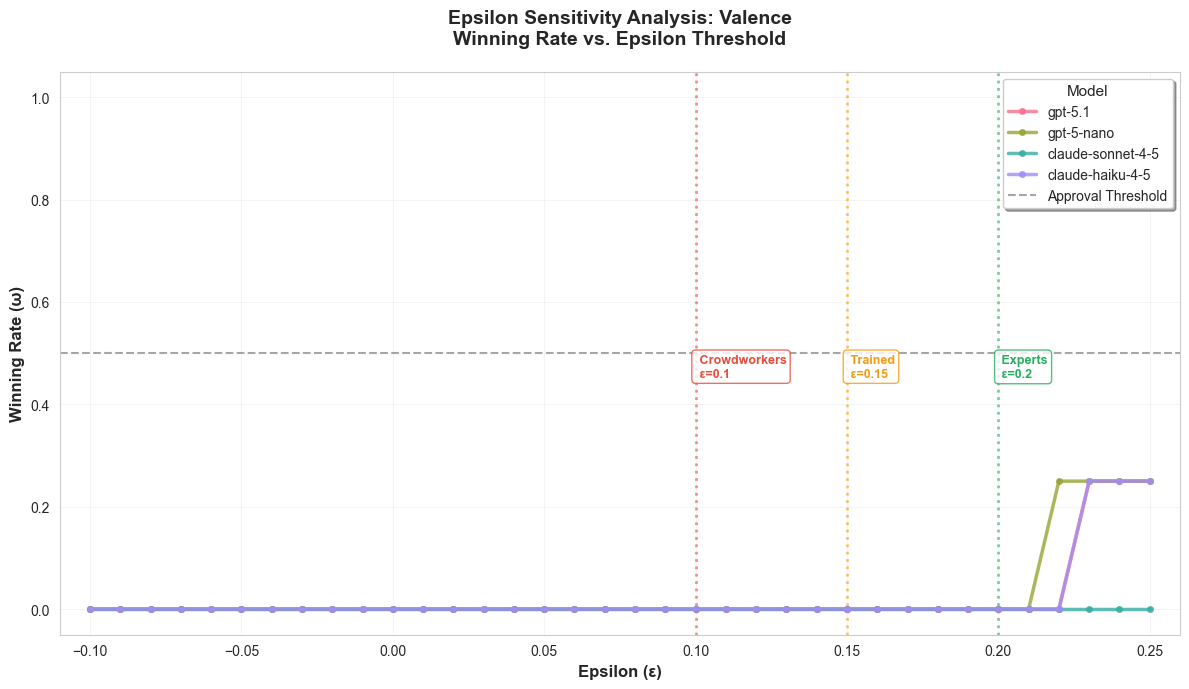

In [34]:
p_val.plot_epsilon_sensitivity()

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.840
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano
[decision_gpt-5-nano] Dropped 1 instances with less than 2 annotators.

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.821
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.765
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.630
Tested against 4 human annotators

Testing all 4 L

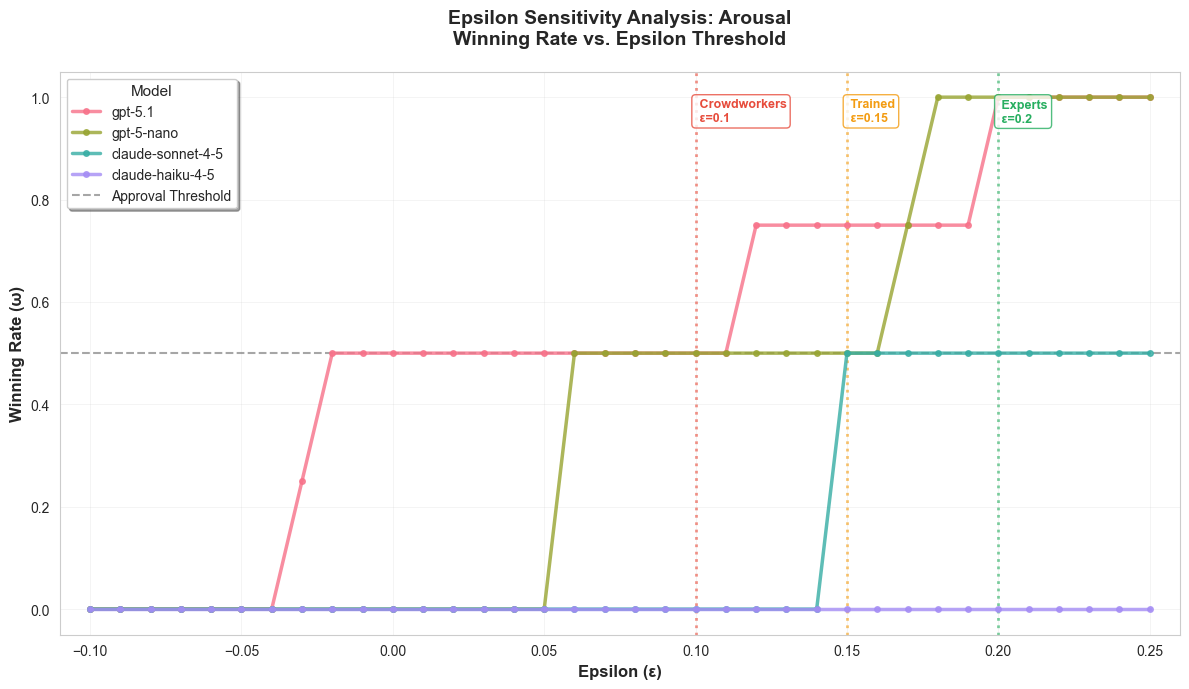

In [35]:
p_aro.plot_epsilon_sensitivity()

Testing 36 epsilon values from -0.1 to 0.25...
Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decision_claude-sonnet-4-5', 'decision_claude-haiku-4-5']
Using LLM decision column: decision_gpt-5.1
Using LLM decision column: decision_gpt-5.1

ALT-TEST RESULTS - GPT-5.1
Winning Rate (ω): 0.000
Advantage Probability: 0.780
Tested against 4 human annotators

Using LLM decision column: decision_gpt-5-nano

ALT-TEST RESULTS - GPT-5-NANO
Winning Rate (ω): 0.000
Advantage Probability: 0.810
Tested against 4 human annotators

Using LLM decision column: decision_claude-sonnet-4-5

ALT-TEST RESULTS - CLAUDE-SONNET-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.775
Tested against 4 human annotators

Using LLM decision column: decision_claude-haiku-4-5

ALT-TEST RESULTS - CLAUDE-HAIKU-4-5
Winning Rate (ω): 0.000
Advantage Probability: 0.790
Tested against 4 human annotators

Testing all 4 LLM decision columns: ['decision_gpt-5.1', 'decision_gpt-5-nano', 'decis

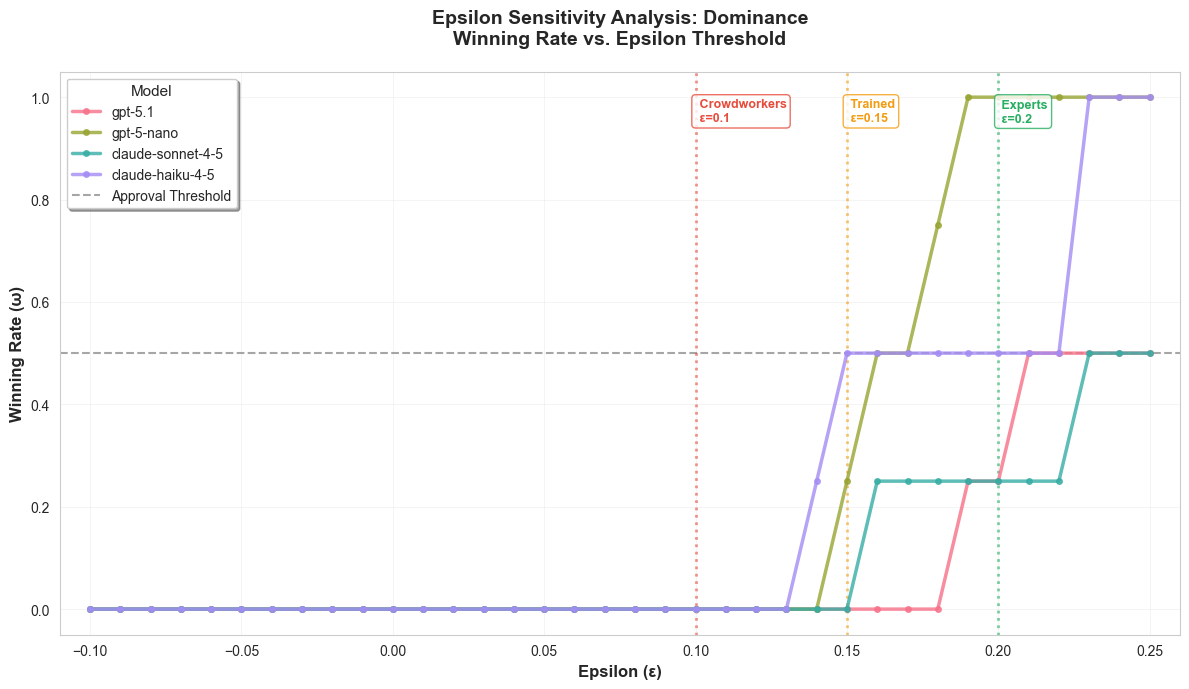

In [36]:
p_dom.plot_epsilon_sensitivity()

# Dawid-Skene (experimental)

In [38]:
p_val.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 46

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 46

Top 5 Most Reliable Annotators:
   rank            annotator  reliability   type
0     1                   A3     0.938036  Human
1     2                   A2     0.888511  Human
2     3  decision_gpt-5-nano     0.834819    LLM
3     4                   A4     0.818847  Human
4     5                   A1     0.785889  Human




,annotator,reliability,type,rank
0,A3,0.938036,Human,1
1,A2,0.888511,Human,2
2,decision_gpt-5-nano,0.834819,LLM,3
3,A4,0.818847,Human,4
4,A1,0.785889,Human,5
5,decision_claude-haiku-4-5,0.743265,LLM,6
6,decision_claude-sonnet-4-5,0.724527,LLM,7
7,decision_gpt-5.1,0.721879,LLM,8


In [39]:
p_aro.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 26

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 26

Top 5 Most Reliable Annotators:
   rank                   annotator  reliability   type
0     1         decision_gpt-5-nano     0.967858    LLM
1     2  decision_claude-sonnet-4-5     0.940686    LLM
2     3            decision_gpt-5.1     0.940486    LLM
3     4                          A3     0.913330  Human
4     5                          A2     0.877920  Human




,annotator,reliability,type,rank
0,decision_gpt-5-nano,0.967858,LLM,1
1,decision_claude-sonnet-4-5,0.940686,LLM,2
2,decision_gpt-5.1,0.940486,LLM,3
3,A3,0.913330,Human,4
4,A2,0.877920,Human,5
5,decision_claude-haiku-4-5,0.836406,LLM,6
6,A4,0.741335,Human,7
7,A1,0.696044,Human,8


In [40]:
p_dom.dawid_skene_annotator_ranking(random_seed=42)

Ranking 8 annotators across 293 instances...
Dawid-Skene converged at iteration 45

DAWID-SKENE ANNOTATOR RANKING
Converged at iteration: 45

Top 5 Most Reliable Annotators:
   rank                   annotator  reliability   type
0     1  decision_claude-sonnet-4-5     0.863831    LLM
1     2         decision_gpt-5-nano     0.849023    LLM
2     3   decision_claude-haiku-4-5     0.824090    LLM
3     4                          A3     0.809395  Human
4     5            decision_gpt-5.1     0.767276    LLM




,annotator,reliability,type,rank
0,decision_claude-sonnet-4-5,0.863831,LLM,1
1,decision_gpt-5-nano,0.849023,LLM,2
2,decision_claude-haiku-4-5,0.824090,LLM,3
3,A3,0.809395,Human,4
4,decision_gpt-5.1,0.767276,LLM,5
5,A2,0.761905,Human,6
6,A4,0.700411,Human,7
7,A1,0.605240,Human,8


# Save pairadigms

In [45]:
today = pd.Timestamp.now().strftime('%m-%d-%y')
p_val.save(f'Results/pairadigms/valence_pairadigm_{today}.pkl')
p_aro.save(f'Results/pairadigms/arousal_pairadigm_{today}.pkl')
p_dom.save(f'Results/pairadigms/dominance_pairadigm_{today}.pkl')

Pairadigm object saved successfully to: Results/pairadigms/valence_pairadigm_12-15-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/arousal_pairadigm_12-15-25.pkl
Pairadigm object saved successfully to: Results/pairadigms/dominance_pairadigm_12-15-25.pkl


In [48]:
today = pd.Timestamp.now().strftime('%m-%d-%y')
# Save pairwise results to CSV
for p in [p_val, p_aro, p_dom]:
    paired_results = p.pairwise_df
    paired_results.to_csv(f'Results/paired_results/{p.target_concept}_paired_results_{today}.csv', index=False)

# Valence AltTest Failure Exploration

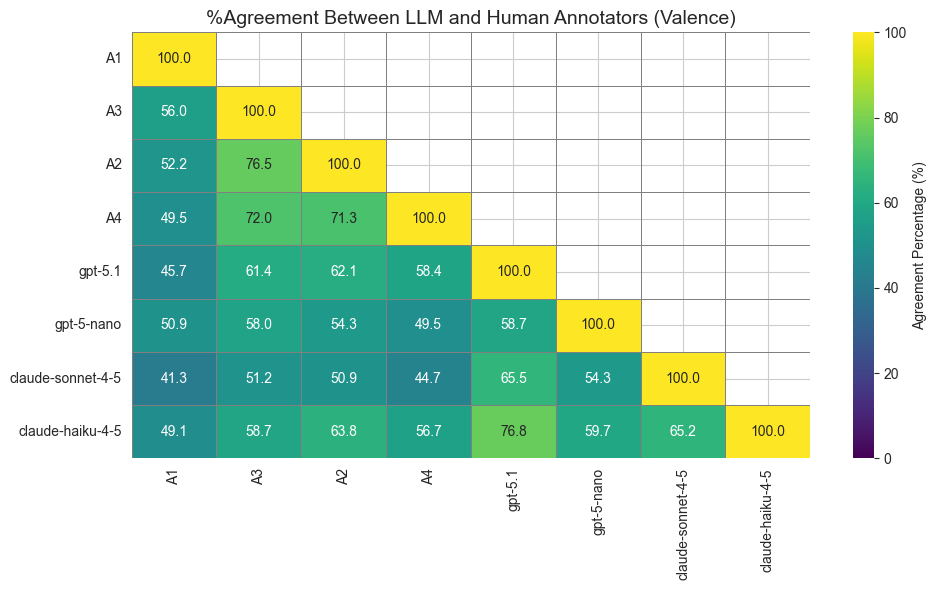

In [46]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Define human and LLM annotators
human_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('A')]
llm_annotators = [col for col in p_val.pairwise_df.columns if col.startswith('decision')]
all_annotators = human_annotators + llm_annotators

# Initialize a matrix to store agreement percentages
agreement_matrix = np.zeros((len(all_annotators), len(all_annotators)))

# Calculate agreement percentages
for i, llm_col in enumerate(all_annotators):
    for j, human_col in enumerate(all_annotators):
        # Calculate percentage of rows where values match
        matches = (p_val.pairwise_df[llm_col] == p_val.pairwise_df[human_col]).sum()
        total = len(p_val.pairwise_df)
        agreement_pct = (matches / total) * 100
        agreement_matrix[i, j] = agreement_pct

# Create clean labels by removing "decision_" prefix
clean_labels = [col.replace('decision_', '') for col in all_annotators]
clean_labels = [col.replace('-20250929', '') for col in clean_labels]

# Create a DataFrame for better labeling
agreement_df = pd.DataFrame(
    agreement_matrix,
    index=clean_labels,
    columns=clean_labels
)

# Create a mask for the upper triangle
import numpy as np
mask = np.triu(np.ones_like(agreement_df, dtype=bool), k=1)

# Plot the heatmap with colorblind-friendly palette
plt.figure(figsize=(10, 6))
sns.heatmap(
    agreement_df,
    annot=True,
    fmt='.1f',
    cmap='viridis',
    vmin=0,
    vmax=100,
    cbar_kws={'label': 'Agreement Percentage (%)'},
    linewidths=0.5,
    linecolor='gray',
    mask=mask
)
plt.title('%Agreement Between LLM and Human Annotators (Valence)', fontsize=14)
plt.tight_layout()
plt.show()